In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import pandas as pd

df = pd.read_csv('/content/simulation synthetic data.csv')

print(df.head())

             timestamp                road  crack_type     crack_type_name  \
0  2024-01-01 00:33:27      A2 Addis-Adama           1  Longitudinal crack   
1  2024-01-01 18:06:37      A2 Addis-Adama           3    Transverse crack   
2  2024-01-02 11:46:17        R2 Ring Road           2              Repair   
3  2024-01-03 04:51:16      A2 Addis-Adama           3    Transverse crack   
4  2024-01-03 22:27:32  A9 Addis-Bahir Dar           2              Repair   

   confidence_pct  crack_area_pct vehicle_type  vehicle_speed_kmh weather  \
0            60.1            5.68  Heavy Truck                 10    rain   
1            52.5            9.31      Bicycle                 18    snow   
2            82.9            2.87  Heavy Truck                 22    snow   
3            46.4           11.71      Bicycle                117    rain   
4            73.1           15.76        Truck                 36    snow   

  tire_condition  temperature_c  humidity_pct  road_age_yr  traffic_

In [ ]:
# Check dataset structure
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (1000, 19)

Column names:
['timestamp', 'road', 'crack_type', 'crack_type_name', 'confidence_pct', 'crack_area_pct', 'vehicle_type', 'vehicle_speed_kmh', 'weather', 'tire_condition', 'temperature_c', 'humidity_pct', 'road_age_yr', 'traffic_volume', 'friction_coeff', 'gps_lat', 'gps_lon', 'severity', 'risk_score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   timestamp          1000 non-null   object 
 1   road               1000 non-null   object 
 2   crack_type         1000 non-null   int64  
 3   crack_type_name    1000 non-null   object 
 4   confidence_pct     1000 non-null   float64
 5   crack_area_pct     1000 non-null   float64
 6   vehicle_type       1000 non-null   object 
 7   vehicle_speed_kmh  1000 non-null   int64  
 8   weather            1000 non-null   object 
 9   tire_cond

In [ ]:
#Checking missing values

print(df.isnull().sum())

timestamp            0
road                 0
crack_type           0
crack_type_name      0
confidence_pct       0
crack_area_pct       0
vehicle_type         0
vehicle_speed_kmh    0
weather              0
tire_condition       0
temperature_c        0
humidity_pct         0
road_age_yr          0
traffic_volume       0
friction_coeff       0
gps_lat              0
gps_lon              0
severity             0
risk_score           0
dtype: int64


In [ ]:
missing_percentage = (df.isnull().mean() * 100).round(2)

print(missing_percentage)

timestamp            0.0
road                 0.0
crack_type           0.0
crack_type_name      0.0
confidence_pct       0.0
crack_area_pct       0.0
vehicle_type         0.0
vehicle_speed_kmh    0.0
weather              0.0
tire_condition       0.0
temperature_c        0.0
humidity_pct         0.0
road_age_yr          0.0
traffic_volume       0.0
friction_coeff       0.0
gps_lat              0.0
gps_lon              0.0
severity             0.0
risk_score           0.0
dtype: float64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
#numerical data examining
print(df.describe())

        crack_type  confidence_pct  crack_area_pct  vehicle_speed_kmh  \
count  1000.000000     1000.000000     1000.000000        1000.000000   
mean      1.502000       71.830200        9.141900          65.135000   
std       1.128392       15.529166        5.200393          36.273883   
min       0.000000       45.100000        0.510000           5.000000   
25%       0.000000       58.675000        4.577500          33.000000   
50%       1.000000       71.700000        9.195000          65.000000   
75%       3.000000       85.500000       13.830000          96.000000   
max       3.000000       98.900000       17.960000         129.000000   

       temperature_c  humidity_pct  road_age_yr  traffic_volume  \
count    1000.000000   1000.000000  1000.000000     1000.000000   
mean       19.765000     55.840000    15.436000        5.492000   
std        14.246499     24.147661     8.740383        2.822038   
min        -5.000000     15.000000     1.000000        1.000000   
25%    

In [ ]:
print("Risk_Score exists:", "risk_score" in df.columns)

Risk_Score exists: True


In [ ]:
#Explore the target variable

if "risk_score" in df.columns:
    print(df["risk_score"].describe())
    print("Missing Risk_Score values:", df["risk_score"].isnull().sum())

count    1000.000000
mean        2.740130
std         2.457986
min         0.060000
25%         0.930000
50%         1.910000
75%         3.682500
max        10.000000
Name: risk_score, dtype: float64
Missing Risk_Score values: 0


In [ ]:
#Examine categorical variables and their frequency

categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 timestamp
timestamp
2024-01-01 00:33:27    1
2024-01-01 18:06:37    1
2024-01-02 11:46:17    1
2024-01-03 04:51:16    1
2024-01-03 22:27:32    1
                      ..
2025-12-27 08:24:07    1
2025-12-28 01:57:11    1
2025-12-28 19:42:26    1
2025-12-29 13:10:55    1
2025-12-30 06:46:47    1
Name: count, Length: 1000, dtype: int64

 road
road
A2 Addis-Adama        212
A9 Addis-Bahir Dar    206
A3 Addis-Jimma        204
A1 Addis-Dire Dawa    196
R2 Ring Road          182
Name: count, dtype: int64

 crack_type_name
crack_type_name
Transverse crack      258
Alligator crack       253
Longitudinal crack    250
Repair                239
Name: count, dtype: int64

 vehicle_type
vehicle_type
Heavy Truck    177
Truck          172
Bicycle        169
Motorcycle     165
Normal Car     161
Minibus        156
Name: count, dtype: int64

 weather
weather
night        189
rain         169
heavyrain    168
fog          168
snow         156
clear        150
Name: count, dtype: int64

 tire_condition


In [ ]:
#severity distribution

print(df['severity'].value_counts())

severity
LOW         596
MODERATE    233
HIGH        114
CRITICAL     57
Name: count, dtype: int64


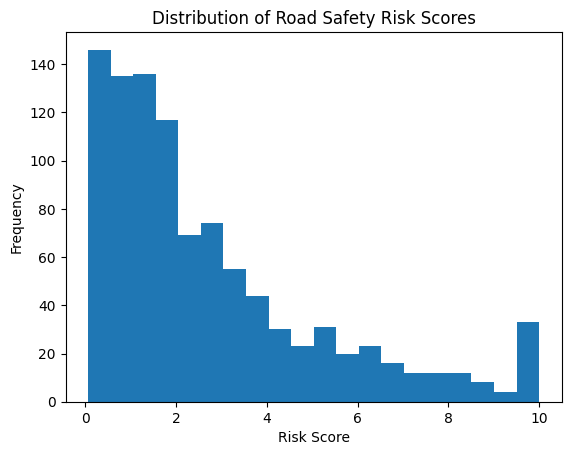

In [ ]:
#risk score distribution in histogram

import matplotlib.pyplot as plt

plt.hist(df['risk_score'], bins=20)

plt.xlabel('Risk Score')
plt.ylabel('Frequency')
plt.title('Distribution of Road Safety Risk Scores')

plt.show()

In [ ]:
#relationships between numerical variables

correlation = df.corr(numeric_only=True)

print(correlation['risk_score'].sort_values(ascending=False))

risk_score           1.000000
vehicle_speed_kmh    0.600933
crack_area_pct       0.460795
humidity_pct         0.047306
temperature_c        0.015181
road_age_yr         -0.003630
traffic_volume      -0.014786
confidence_pct      -0.018165
gps_lat             -0.020529
gps_lon             -0.022271
crack_type          -0.160551
friction_coeff      -0.281920
Name: risk_score, dtype: float64


In [ ]:
#Data Investigation & Preprocessing ---WEEK 3

In [ ]:
print("DATASET INFORMATION")

print("\nFirst five records:")
display(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

DATASET INFORMATION

First five records:


,timestamp,road,crack_type,crack_type_name,confidence_pct,crack_area_pct,vehicle_type,vehicle_speed_kmh,weather,tire_condition,temperature_c,humidity_pct,road_age_yr,traffic_volume,friction_coeff,gps_lat,gps_lon,severity,risk_score
0,2024-01-01 00:33:27,A2 Addis-Adama,1,Longitudinal crack,60.1,5.68,Heavy Truck,10,rain,worn,31,30,15,7,0.306,9.0569,38.7374,LOW,0.27
1,2024-01-01 18:06:37,A2 Addis-Adama,3,Transverse crack,52.5,9.31,Bicycle,18,snow,good,26,50,24,2,0.238,9.0651,38.7061,LOW,0.94
2,2024-01-02 11:46:17,R2 Ring Road,2,Repair,82.9,2.87,Heavy Truck,22,snow,good,6,34,20,8,0.244,9.0311,38.7717,LOW,0.23
3,2024-01-03 04:51:16,A2 Addis-Adama,3,Transverse crack,46.4,11.71,Bicycle,117,rain,worn,11,25,14,6,0.300,8.9962,38.7295,HIGH,6.93
4,2024-01-03 22:27:32,A9 Addis-Bahir Dar,2,Repair,73.1,15.76,Truck,36,snow,good,23,85,24,9,0.234,9.2517,38.5721,LOW,1.26



Dataset shape:
(1000, 19)

Column names:
['timestamp', 'road', 'crack_type', 'crack_type_name', 'confidence_pct', 'crack_area_pct', 'vehicle_type', 'vehicle_speed_kmh', 'weather', 'tire_condition', 'temperature_c', 'humidity_pct', 'road_age_yr', 'traffic_volume', 'friction_coeff', 'gps_lat', 'gps_lon', 'severity', 'risk_score']

Data types:
timestamp             object
road                  object
crack_type             int64
crack_type_name       object
confidence_pct       float64
crack_area_pct       float64
vehicle_type          object
vehicle_speed_kmh      int64
weather               object
tire_condition        object
temperature_c          int64
humidity_pct           int64
road_age_yr            int64
traffic_volume         int64
friction_coeff       float64
gps_lat              float64
gps_lon              float64
severity              object
risk_score           float64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 

In [ ]:
# DATA INVESTIGATION
# Analyze risk score by severity

print("RISK SCORE STATISTICS BY SEVERITY")

severity_analysis = df.groupby('severity')['risk_score'].agg(
    ['count', 'mean', 'min', 'max', 'std']
)

print(severity_analysis.round(2))

RISK SCORE STATISTICS BY SEVERITY
          count  mean   min    max   std
severity                                
CRITICAL     57  9.38  8.05  10.00  0.74
HIGH        114  6.24  5.04   7.99  0.84
LOW         596  1.14  0.06   2.50  0.66
MODERATE    233  3.48  2.51   4.98  0.68


In [ ]:
#Correlation analysis with risk score
correlation = df.corr(numeric_only=True)

risk_correlation = correlation['risk_score'].sort_values(
    ascending=False
)

print("CORRELATION WITH RISK SCORE")
print(risk_correlation.round(3))

CORRELATION WITH RISK SCORE
risk_score           1.000
vehicle_speed_kmh    0.601
crack_area_pct       0.461
humidity_pct         0.047
temperature_c        0.015
road_age_yr         -0.004
traffic_volume      -0.015
confidence_pct      -0.018
gps_lat             -0.021
gps_lon             -0.022
crack_type          -0.161
friction_coeff      -0.282
Name: risk_score, dtype: float64


In [ ]:
# Investigate potential outliers by using the Interquartile Range (IQR) method.

numerical_columns = [
    'confidence_pct',
    'crack_area_pct',
    'vehicle_speed_kmh',
    'temperature_c',
    'humidity_pct',
    'road_age_yr',
    'traffic_volume',
    'friction_coeff',
    'gps_lat',
    'gps_lon',
    'risk_score'
]

print("POTENTIAL OUTLIER INVESTIGATION")

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Potential outliers:", len(outliers))
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))

POTENTIAL OUTLIER INVESTIGATION

Column: confidence_pct
Potential outliers: 0
Lower limit: 18.44
Upper limit: 125.74

Column: crack_area_pct
Potential outliers: 0
Lower limit: -9.3
Upper limit: 27.71

Column: vehicle_speed_kmh
Potential outliers: 0
Lower limit: -61.5
Upper limit: 190.5

Column: temperature_c
Potential outliers: 0
Lower limit: -28.0
Upper limit: 68.0

Column: humidity_pct
Potential outliers: 0
Lower limit: -28.0
Upper limit: 140.0

Column: road_age_yr
Potential outliers: 0
Lower limit: -14.5
Upper limit: 45.5

Column: traffic_volume
Potential outliers: 0
Lower limit: -4.5
Upper limit: 15.5

Column: friction_coeff
Potential outliers: 0
Lower limit: -0.22
Upper limit: 0.91

Column: gps_lat
Potential outliers: 204
Lower limit: 8.77
Upper limit: 9.36

Column: gps_lon
Potential outliers: 400
Lower limit: 38.28
Upper limit: 39.08

Column: risk_score
Potential outliers: 63
Lower limit: -3.2
Upper limit: 7.81


In [ ]:
# Examine categorical variables

categorical_columns = [
    'crack_type',
    'crack_type_name',
    'vehicle_type',
    'weather',
    'tire_condition',
    'road',
    'severity'
]

print("CATEGORICAL VARIABLE ANALYSIS")

for col in categorical_columns:

    print(f"\nVariable: {col}")

    print(df[col].value_counts())

    print("Number of unique categories:", df[col].nunique())

CATEGORICAL VARIABLE ANALYSIS

Variable: crack_type
crack_type
3    258
0    253
1    250
2    239
Name: count, dtype: int64
Number of unique categories: 4

Variable: crack_type_name
crack_type_name
Transverse crack      258
Alligator crack       253
Longitudinal crack    250
Repair                239
Name: count, dtype: int64
Number of unique categories: 4

Variable: vehicle_type
vehicle_type
Heavy Truck    177
Truck          172
Bicycle        169
Motorcycle     165
Normal Car     161
Minibus        156
Name: count, dtype: int64
Number of unique categories: 6

Variable: weather
weather
night        189
rain         169
heavyrain    168
fog          168
snow         156
clear        150
Name: count, dtype: int64
Number of unique categories: 6

Variable: tire_condition
tire_condition
good    343
bad     331
worn    326
Name: count, dtype: int64
Number of unique categories: 3

Variable: road
road
A2 Addis-Adama        212
A9 Addis-Bahir Dar    206
A3 Addis-Jimma        204
A1 Addis-Dire

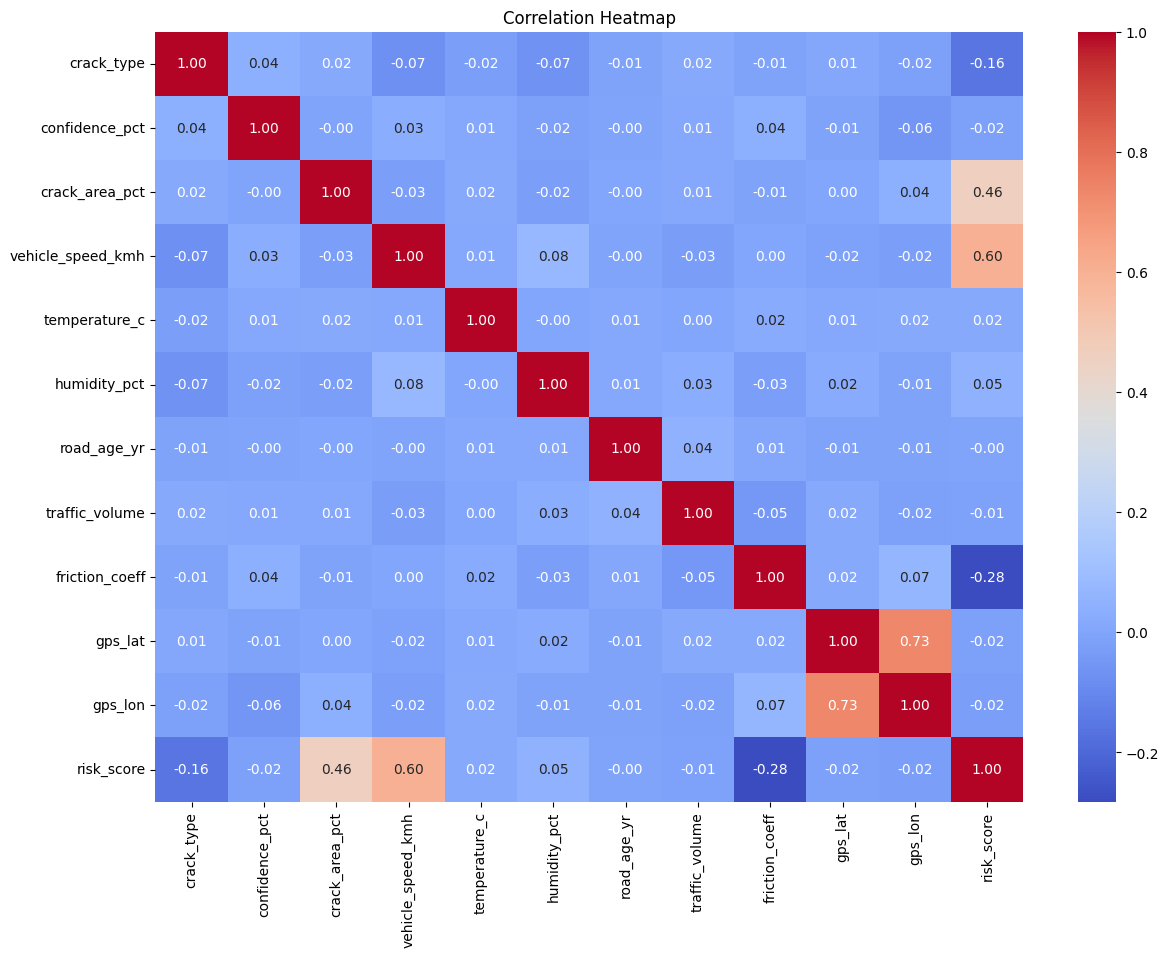

In [ ]:
# correlation heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

In [ ]:
# Investigate possible data leakage

print("TARGET LEAKAGE INVESTIGATION")

print("\nSeverity and risk score relationship:")

print(
    df.groupby('severity')['risk_score']
    .agg(['count', 'min', 'max', 'mean'])
    .round(2)
)

print("\nOverall risk score statistics:")

print(df['risk_score'].describe())

TARGET LEAKAGE INVESTIGATION

Severity and risk score relationship:
          count   min    max  mean
severity                          
CRITICAL     57  8.05  10.00  9.38
HIGH        114  5.04   7.99  6.24
LOW         596  0.06   2.50  1.14
MODERATE    233  2.51   4.98  3.48

Overall risk score statistics:
count    1000.000000
mean        2.740130
std         2.457986
min         0.060000
25%         0.930000
50%         1.910000
75%         3.682500
max        10.000000
Name: risk_score, dtype: float64


In [ ]:
#Checking invalid values for data quality

print("INVALID VALUE INVESTIGATION")

checks = {
    'Confidence below 0': df['confidence_pct'] < 0,
    'Confidence above 100': df['confidence_pct'] > 100,

    'Crack area below 0': df['crack_area_pct'] < 0,
    'Crack area above 100': df['crack_area_pct'] > 100,

    'Negative vehicle speed': df['vehicle_speed_kmh'] < 0,

    'Humidity below 0': df['humidity_pct'] < 0,
    'Humidity above 100': df['humidity_pct'] > 100,

    'Negative road age': df['road_age_yr'] < 0,

    'Negative traffic volume': df['traffic_volume'] < 0,

    'Friction below 0': df['friction_coeff'] < 0,
    'Friction above 1': df['friction_coeff'] > 1,

    'Risk score below 0': df['risk_score'] < 0,
    'Risk score above 10': df['risk_score'] > 10,

    'Invalid GPS latitude': (
        (df['gps_lat'] < -90) | (df['gps_lat'] > 90)
    ),

    'Invalid GPS longitude': (
        (df['gps_lon'] < -180) | (df['gps_lon'] > 180)
    )
}

for name, condition in checks.items():

    print(f"{name}: {condition.sum()}")

INVALID VALUE INVESTIGATION
Confidence below 0: 0
Confidence above 100: 0
Crack area below 0: 0
Crack area above 100: 0
Negative vehicle speed: 0
Humidity below 0: 0
Humidity above 100: 0
Negative road age: 0
Negative traffic volume: 0
Friction below 0: 0
Friction above 1: 0
Risk score below 0: 0
Risk score above 10: 0
Invalid GPS latitude: 0
Invalid GPS longitude: 0


In [ ]:
#Check constant and low-variance features to help us identify variables that contain very little variation.

print("UNIQUE VALUES IN EACH COLUMN")

print(df.nunique())

print("\nNUMERICAL FEATURE VARIANCE")

print(
    df[numerical_columns[:-1]]
    .var()
    .sort_values()
)

UNIQUE VALUES IN EACH COLUMN
timestamp            1000
road                    5
crack_type              4
crack_type_name         4
confidence_pct        461
crack_area_pct        768
vehicle_type            6
vehicle_speed_kmh     125
weather                 6
tire_condition          3
temperature_c          50
humidity_pct           84
road_age_yr            30
traffic_volume         10
friction_coeff        303
gps_lat               870
gps_lon               859
severity                4
risk_score            494
dtype: int64

NUMERICAL FEATURE VARIANCE
friction_coeff          0.035370
gps_lat                 0.056032
gps_lon                 0.107353
traffic_volume          7.963900
crack_area_pct         27.044091
road_age_yr            76.394298
temperature_c         202.962738
confidence_pct        241.154983
humidity_pct          583.109510
vehicle_speed_kmh    1315.794570
dtype: float64


In [ ]:
#Analyze numerical skewness

print("NUMERICAL VARIABLE SKEWNESS")

skewness = df[numerical_columns].skew()

print(skewness.sort_values(ascending=False).round(3))

NUMERICAL VARIABLE SKEWNESS
risk_score           1.336
friction_coeff       0.625
humidity_pct         0.073
road_age_yr          0.066
vehicle_speed_kmh    0.036
confidence_pct       0.012
crack_area_pct       0.002
traffic_volume      -0.013
temperature_c       -0.033
gps_lon             -0.324
gps_lat             -0.975
dtype: float64


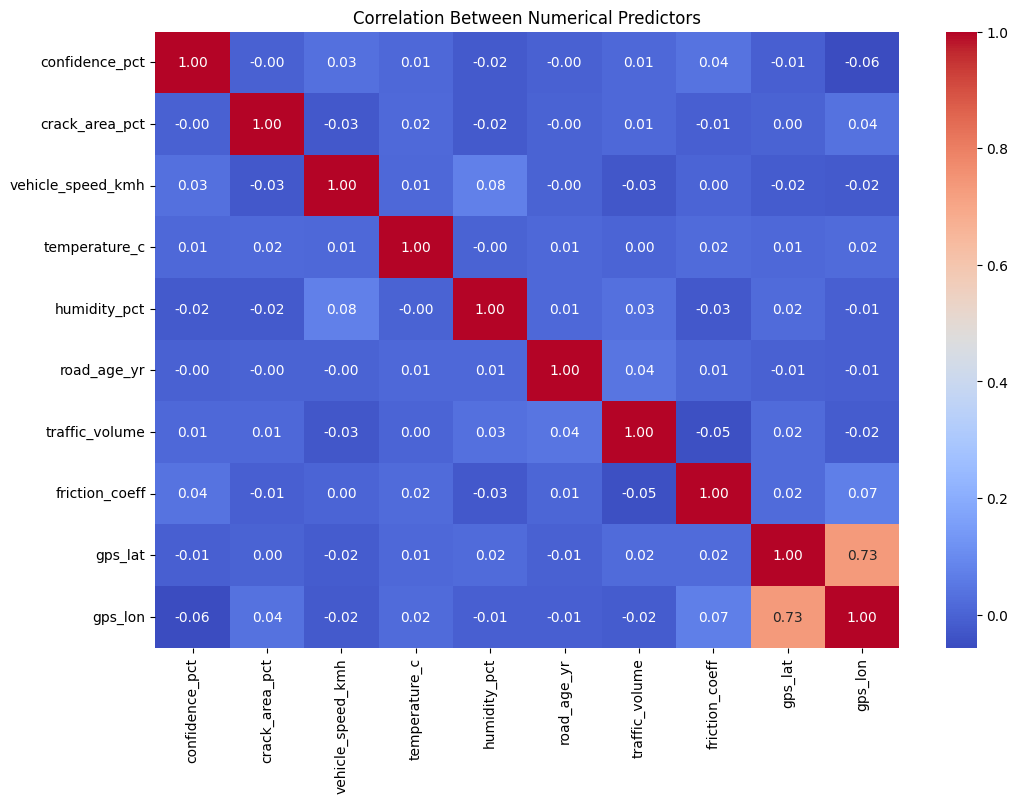

In [ ]:
#Investigate multicollinearity
# we examine correlations between numerical predictors, not the target.

numeric_predictors = [
    'confidence_pct',
    'crack_area_pct',
    'vehicle_speed_kmh',
    'temperature_c',
    'humidity_pct',
    'road_age_yr',
    'traffic_volume',
    'friction_coeff',
    'gps_lat',
    'gps_lon'
]

predictor_correlation = df[numeric_predictors].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    predictor_correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Numerical Predictors')

plt.show()

In [ ]:
#FEATURE SELECTION
#Selecting predictors and target
target = 'risk_score'

excluded_columns = [
    'risk_score',
    'severity',
    'timestamp',
    'crack_type_name'
]

X = df.drop(columns=excluded_columns)

y = df[target]

print("SELECTED PREDICTOR VARIABLES")

print(X.columns.tolist())

print("\nNumber of predictors:", X.shape[1])

print("\nTarget variable:", target)

print("Target shape:", y.shape)

SELECTED PREDICTOR VARIABLES
['road', 'crack_type', 'confidence_pct', 'crack_area_pct', 'vehicle_type', 'vehicle_speed_kmh', 'weather', 'tire_condition', 'temperature_c', 'humidity_pct', 'road_age_yr', 'traffic_volume', 'friction_coeff', 'gps_lat', 'gps_lon']

Number of predictors: 15

Target variable: risk_score
Target shape: (1000,)


In [ ]:
#Separate numerical and categorical features

numerical_features = [
    'confidence_pct',
    'crack_area_pct',
    'vehicle_speed_kmh',
    'temperature_c',
    'humidity_pct',
    'road_age_yr',
    'traffic_volume',
    'friction_coeff',
    'gps_lat',
    'gps_lon'
]

categorical_features = [
    'crack_type',
    'vehicle_type',
    'weather',
    'tire_condition',
    'road'
]

print("NUMERICAL FEATURES")

print(numerical_features)

print("\nNumber of numerical features:")
print(len(numerical_features))

print("\nCATEGORICAL FEATURES")

print(categorical_features)

print("\nNumber of categorical features:")
print(len(categorical_features))

print("\nTotal selected features:")
print(len(numerical_features) + len(categorical_features))

NUMERICAL FEATURES
['confidence_pct', 'crack_area_pct', 'vehicle_speed_kmh', 'temperature_c', 'humidity_pct', 'road_age_yr', 'traffic_volume', 'friction_coeff', 'gps_lat', 'gps_lon']

Number of numerical features:
10

CATEGORICAL FEATURES
['crack_type', 'vehicle_type', 'weather', 'tire_condition', 'road']

Number of categorical features:
5

Total selected features:
15


In [ ]:
print("FEATURE SELECTION VERIFICATION")

print("\nPredictor shape:", X.shape)

print("\nMissing values in predictors:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

print("\nNumerical feature data types:")
print(X[numerical_features].dtypes)

print("\nCategorical feature data types:")
print(X[categorical_features].dtypes)

FEATURE SELECTION VERIFICATION

Predictor shape: (1000, 15)

Missing values in predictors:
road                 0
crack_type           0
confidence_pct       0
crack_area_pct       0
vehicle_type         0
vehicle_speed_kmh    0
weather              0
tire_condition       0
temperature_c        0
humidity_pct         0
road_age_yr          0
traffic_volume       0
friction_coeff       0
gps_lat              0
gps_lon              0
dtype: int64

Missing values in target:
0

Numerical feature data types:
confidence_pct       float64
crack_area_pct       float64
vehicle_speed_kmh      int64
temperature_c          int64
humidity_pct           int64
road_age_yr            int64
traffic_volume         int64
friction_coeff       float64
gps_lat              float64
gps_lon              float64
dtype: object

Categorical feature data types:
crack_type         int64
vehicle_type      object
weather           object
tire_condition    object
road              object
dtype: object


In [ ]:
# TRAINING AND TESTING SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("TRAINING AND TESTING SPLIT")

print("\nTraining predictors:", X_train.shape)

print("Testing predictors:", X_test.shape)

print("\nTraining target:", y_train.shape)

print("Testing target:", y_test.shape)

TRAINING AND TESTING SPLIT

Training predictors: (800, 15)
Testing predictors: (200, 15)

Training target: (800,)
Testing target: (200,)


In [ ]:
# DATA PREPROCESSING
#Creating numerical preprocessing pipeline

numerical_transformer = Pipeline(steps=[

    ('imputer', SimpleImputer(strategy='median')),

    ('scaler', StandardScaler())

])

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


In [ ]:
#Createing categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[

    ('imputer', SimpleImputer(strategy='most_frequent')),

    ('encoder', OneHotEncoder(handle_unknown='ignore'))

])

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


In [ ]:
# Combining preprocessing pipelines

preprocessor = ColumnTransformer(

    transformers=[

        ('num', numerical_transformer, numerical_features),

        ('cat', categorical_transformer, categorical_features)

    ]

)

print("Complete preprocessing pipeline created successfully!")

Complete preprocessing pipeline created successfully!


In [ ]:
# Fit and transform training and testing data

# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("PREPROCESSING COMPLETED SUCCESSFULLY!")

print("\nProcessed training data shape:")
print(X_train_processed.shape)

print("\nProcessed testing data shape:")
print(X_test_processed.shape)

PREPROCESSING COMPLETED SUCCESSFULLY!

Processed training data shape:
(800, 34)

Processed testing data shape:
(200, 34)


In [ ]:
# Validate processed data

from scipy import sparse

def check_processed_data(data):

    if sparse.issparse(data):
        values = data.data
    else:
        values = np.asarray(data)

    return {
        'Missing values': np.isnan(values).sum(),
        'Infinite values': np.isinf(values).sum()
    }


print("FINAL PROCESSED DATA VALIDATION")

print("\nTraining data:")
print(check_processed_data(X_train_processed))

print("\nTesting data:")
print(check_processed_data(X_test_processed))

print("\nTraining records:", X_train_processed.shape[0])

print("Testing records:", X_test_processed.shape[0])

print("\nTraining target missing values:", y_train.isnull().sum())

print("Testing target missing values:", y_test.isnull().sum())

FINAL PROCESSED DATA VALIDATION

Training data:
{'Missing values': np.int64(0), 'Infinite values': np.int64(0)}

Testing data:
{'Missing values': np.int64(0), 'Infinite values': np.int64(0)}

Training records: 800
Testing records: 200

Training target missing values: 0
Testing target missing values: 0


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("FINAL PROCESSED FEATURE NAMES")

for feature in feature_names:
    print(feature)

print("\nTotal processed features:")
print(len(feature_names))

FINAL PROCESSED FEATURE NAMES
num__confidence_pct
num__crack_area_pct
num__vehicle_speed_kmh
num__temperature_c
num__humidity_pct
num__road_age_yr
num__traffic_volume
num__friction_coeff
num__gps_lat
num__gps_lon
cat__crack_type_0
cat__crack_type_1
cat__crack_type_2
cat__crack_type_3
cat__vehicle_type_Bicycle
cat__vehicle_type_Heavy Truck
cat__vehicle_type_Minibus
cat__vehicle_type_Motorcycle
cat__vehicle_type_Normal Car
cat__vehicle_type_Truck
cat__weather_clear
cat__weather_fog
cat__weather_heavyrain
cat__weather_night
cat__weather_rain
cat__weather_snow
cat__tire_condition_bad
cat__tire_condition_good
cat__tire_condition_worn
cat__road_A1 Addis-Dire Dawa
cat__road_A2 Addis-Adama
cat__road_A3 Addis-Jimma
cat__road_A9 Addis-Bahir Dar
cat__road_R2 Ring Road

Total processed features:
34


In [ ]:
#Train regression models
#We will train three models:
#PLS Regression: Our proposed main model.
#Linear Regression: Our baseline comparison model.
#Random Forest Regression: A model that can capture nonlinear relationships.


In [ ]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import pandas as pd

In [ ]:
#Train PLS Regression
pls_model = PLSRegression(n_components=2)

pls_model.fit(X_train_processed, y_train)

print("PLS Regression model trained successfully!")

PLS Regression model trained successfully!


In [ ]:
#Train Linear Regression
linear_model = LinearRegression()

linear_model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
#Train Random Forest Regression
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
#Evaluate the models

In [ ]:
#Make predictions
pls_predictions = pls_model.predict(X_test_processed).ravel()

linear_predictions = linear_model.predict(X_test_processed).ravel()

rf_predictions = rf_model.predict(X_test_processed)

In [ ]:
models = {
    "PLS Regression": pls_predictions,
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions
}

results = []

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

               Model     MAE     MSE    RMSE      R2
0     PLS Regression  0.8801  1.3347  1.1553  0.8031
1  Linear Regression  0.8659  1.2636  1.1241  0.8136
2      Random Forest  0.4388  0.4707  0.6861  0.9306


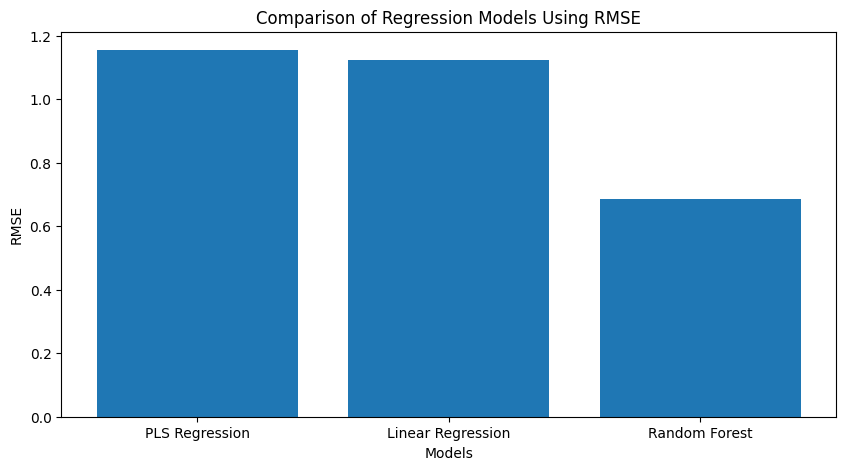

In [ ]:
#Compare model errors by visualization

plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["RMSE"])

plt.title("Comparison of Regression Models Using RMSE")
plt.xlabel("Models")
plt.ylabel("RMSE")

plt.show()

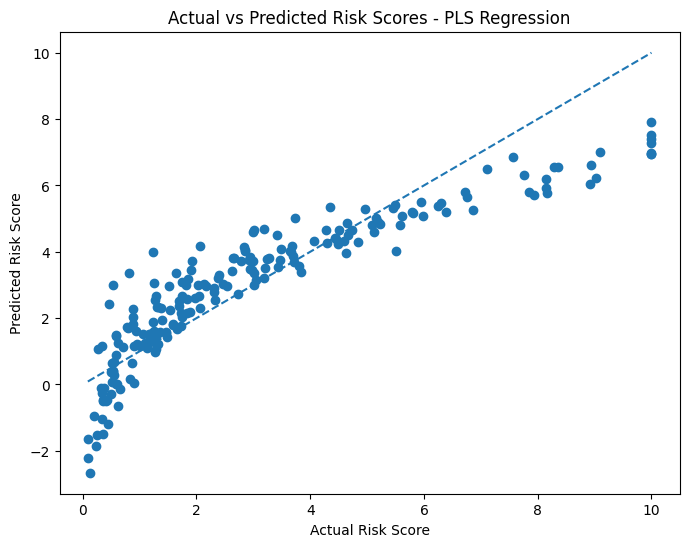

In [ ]:
#Compare actual and predicted values
# Points close to the diagonal line indicate better predictions.
# Points far from the line indicate larger prediction errors.
plt.figure(figsize=(8, 6))

plt.scatter(y_test, pls_predictions)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Risk Score")
plt.ylabel("Predicted Risk Score")

plt.title("Actual vs Predicted Risk Scores - PLS Regression")

plt.show()

In [ ]:
#Improve the PLS model
#Find the best PLS components
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline

pls_pipeline = Pipeline([
    ("pls", PLSRegression())
])

param_grid = {
    "pls__n_components": list(
        range(1, min(11, X_train_processed.shape[1] + 1))
    )
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    pls_pipeline,
    param_grid,
    cv=cv,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train_processed, y_train)

print("Best PLS components:", grid_search.best_params_)

print("Best cross-validation RMSE:",
      np.sqrt(-grid_search.best_score_))

Best PLS components: {'pls__n_components': 7}
Best cross-validation RMSE: 1.0601887007961184


In [ ]:
#Evaluate the improved PLS model
best_pls_model = grid_search.best_estimator_

best_pls_predictions = best_pls_model.predict(
    X_test_processed
).ravel()

print("Improved PLS Model Results")

print("MAE:",
      mean_absolute_error(y_test, best_pls_predictions))

print("MSE:",
      mean_squared_error(y_test, best_pls_predictions))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, best_pls_predictions)))

print("R2:",
      r2_score(y_test, best_pls_predictions))

Improved PLS Model Results
MAE: 0.861382297999286
MSE: 1.2636541379892596
RMSE: 1.1241237200545409
R2: 0.8136243826951667


In [ ]:
#Identify important road safety factors
#Feature importance for Random forest
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

                     Feature  Importance
2     num__vehicle_speed_kmh    0.386603
1        num__crack_area_pct    0.297425
7        num__friction_coeff    0.121380
12         cat__crack_type_2    0.113350
10         cat__crack_type_0    0.017293
11         cat__crack_type_1    0.012158
8               num__gps_lat    0.006224
4          num__humidity_pct    0.005710
3         num__temperature_c    0.005664
0        num__confidence_pct    0.005534
5           num__road_age_yr    0.005302
9               num__gps_lon    0.004553
6        num__traffic_volume    0.004342
13         cat__crack_type_3    0.001473
27  cat__tire_condition_good    0.001331


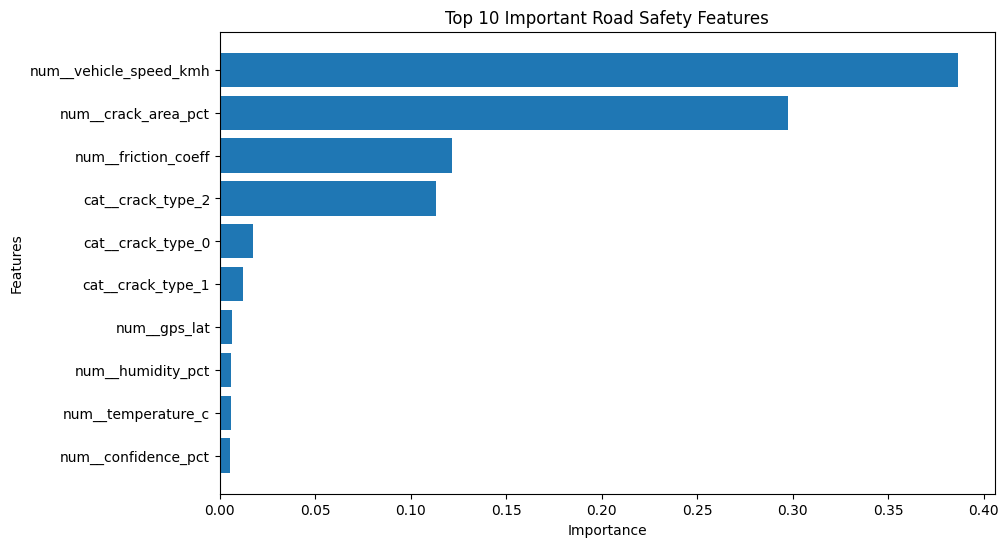

In [ ]:
#Visualize important features
top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")

plt.title("Top 10 Important Road Safety Features")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
#Save the best PLS model
import joblib

joblib.dump(
    best_pls_model,
    "best_pls_model.pkl"
)

joblib.dump(
    preprocessor,
    "road_safety_preprocessor.pkl"
)

print("Model and preprocessing pipeline saved successfully!")

Model and preprocessing pipeline saved successfully!


In [ ]:
#save the evaluation results
results_df.to_csv(
    "model_evaluation_results.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [ ]:
#Final cross-validation and model comparison
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Create model pipelines using our existing preprocessor

original_pls = Pipeline([
    ("preprocessor", preprocessor),
    ("model", PLSRegression(n_components=2))
])

tuned_pls_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", PLSRegression())
])

linear_model_final = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

random_forest_final = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# 2. Prepare tuned PLS model

pls_search = GridSearchCV(
    tuned_pls_pipeline,
    {"model__n_components": range(1, 11)},
    cv=3,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# 3. Define four models

models = {
    "Original PLS": original_pls,
    "Tuned PLS": pls_search,
    "Linear Regression": linear_model_final,
    "Random Forest": random_forest_final
}

# 4. Perform five-fold cross-validation

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    print("Evaluating:", name)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "MSE": "neg_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    mse = -scores["test_MSE"]
    rmse = np.sqrt(mse)

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_MAE"].mean(),
        "Mean MSE": mse.mean(),
        "Mean RMSE": rmse.mean(),
        "RMSE Std": rmse.std(),
        "Mean R2": scores["test_R2"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print("\nFIVE-FOLD CROSS-VALIDATION RESULTS")
print(cv_results_df.round(4))

# 5. Train all four models on the complete training data

for name, model in models.items():

    print("\nTraining:", name)
    model.fit(X_train, y_train)

# 6. Make predictions on the untouched test data

predictions = {}

for name, model in models.items():

    predictions[name] = model.predict(X_test).ravel()

#Final test-set comparison

final_results = []

for name, pred in predictions.items():

    final_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

final_results_df = pd.DataFrame(final_results)

print("\nFINAL TEST-SET MODEL COMPARISON")
print(final_results_df.round(4))

print("\nBest PLS components:")
print(pls_search.best_params_)

Evaluating: Original PLS
Evaluating: Tuned PLS
Evaluating: Linear Regression
Evaluating: Random Forest

FIVE-FOLD CROSS-VALIDATION RESULTS
               Model  Mean MAE  Mean MSE  Mean RMSE  RMSE Std  Mean R2
0       Original PLS    0.8313    1.2186     1.1032    0.0378   0.7903
1          Tuned PLS    0.8102    1.1344     1.0644    0.0397   0.8049
2  Linear Regression    0.8112    1.1303     1.0624    0.0391   0.8056
3      Random Forest    0.4676    0.4698     0.6818    0.0703   0.9198

Training: Original PLS

Training: Tuned PLS

Training: Linear Regression

Training: Random Forest

FINAL TEST-SET MODEL COMPARISON
               Model     MAE     MSE    RMSE      R2
0       Original PLS  0.8801  1.3347  1.1553  0.8031
1          Tuned PLS  0.8614  1.2637  1.1241  0.8136
2  Linear Regression  0.8659  1.2636  1.1241  0.8136
3      Random Forest  0.4388  0.4707  0.6861  0.9306

Best PLS components:
{'model__n_components': 7}


RANDOM FOREST ERROR STATISTICS
count    200.0000
mean       0.4388
std        0.5288
min        0.0004
25%        0.1017
50%        0.2481
75%        0.5574
max        3.1151
Name: Absolute Error, dtype: float64


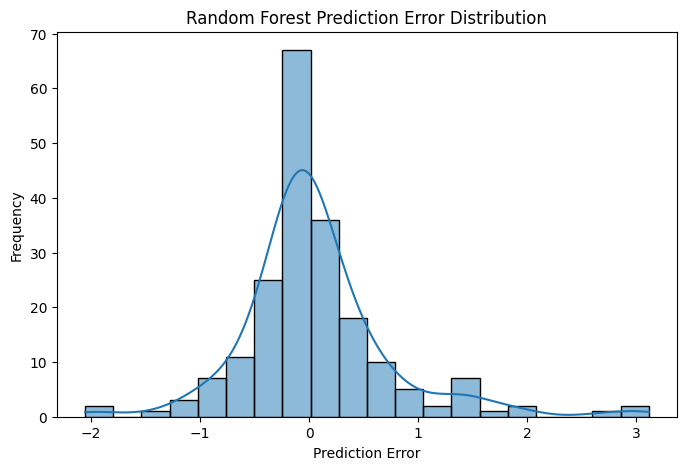

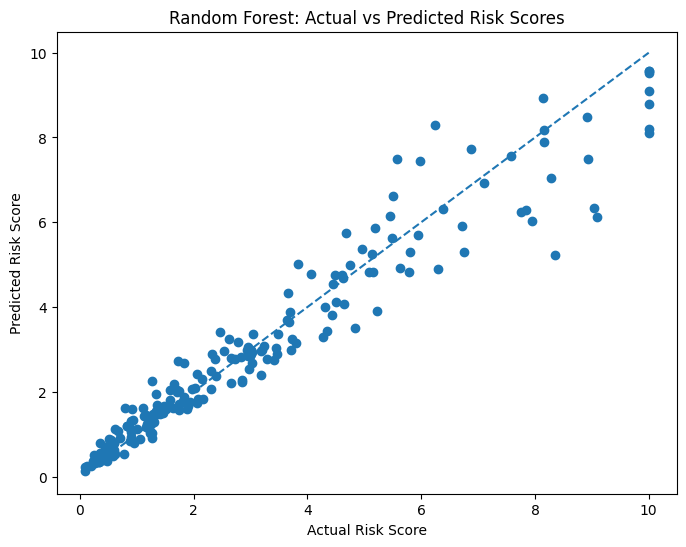


TOP 15 IMPORTANT FEATURES
                     Feature  Importance
2     num__vehicle_speed_kmh      0.3866
1        num__crack_area_pct      0.2974
7        num__friction_coeff      0.1214
12         cat__crack_type_2      0.1133
10         cat__crack_type_0      0.0173
11         cat__crack_type_1      0.0122
8               num__gps_lat      0.0062
4          num__humidity_pct      0.0057
3         num__temperature_c      0.0057
0        num__confidence_pct      0.0055
5           num__road_age_yr      0.0053
9               num__gps_lon      0.0046
6        num__traffic_volume      0.0043
13         cat__crack_type_3      0.0015
27  cat__tire_condition_good      0.0013


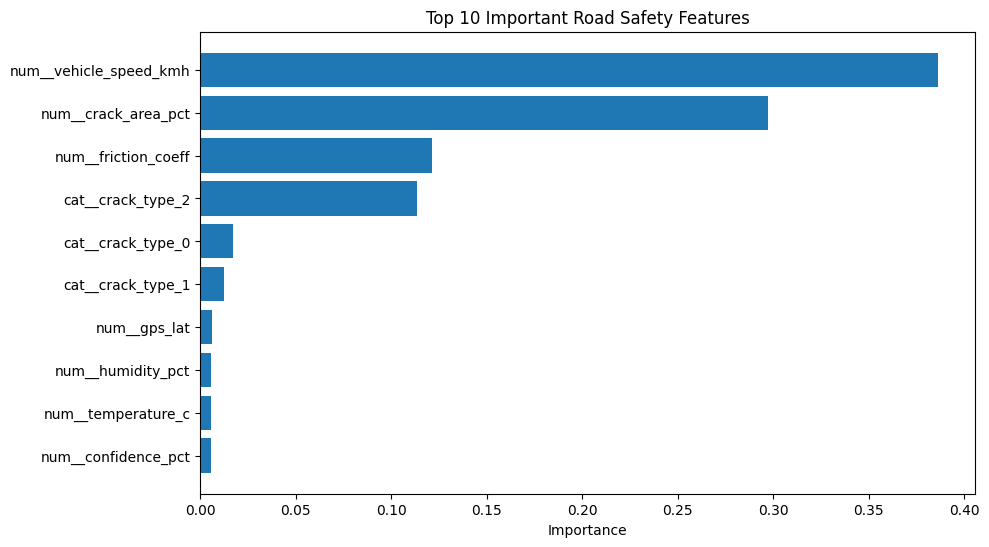


All final results and models saved successfully!


In [ ]:
#Random Forest errors, feature importance, and saving
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Analyze Random Forest prediction errors

rf_predictions = predictions["Random Forest"]

error_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": rf_predictions
})

error_df["Error"] = error_df["Actual"] - error_df["Predicted"]
error_df["Absolute Error"] = error_df["Error"].abs()

print("RANDOM FOREST ERROR STATISTICS")
print(error_df["Absolute Error"].describe().round(4))

# Visualize prediction errors

plt.figure(figsize=(8, 5))

sns.histplot(error_df["Error"], bins=20, kde=True)

plt.title("Random Forest Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

# Actual vs predicted values

plt.figure(figsize=(8, 6))

plt.scatter(error_df["Actual"], error_df["Predicted"])

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Random Forest: Actual vs Predicted Risk Scores")
plt.xlabel("Actual Risk Score")
plt.ylabel("Predicted Risk Score")

plt.show()

# Random Forest feature importance

rf_fitted = random_forest_final

feature_names = rf_fitted.named_steps["preprocessor"].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_fitted.named_steps["model"].feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nTOP 15 IMPORTANT FEATURES")
print(importance_df.head(15).round(4))

#Visualize top 10 features

top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Important Road Safety Features")
plt.xlabel("Importance")

plt.gca().invert_yaxis()

plt.show()

# Save final results

final_results_df.to_csv("final_model_comparison.csv", index=False)

cv_results_df.to_csv("five_fold_cross_validation.csv", index=False)

error_df.to_csv("random_forest_prediction_errors.csv", index=False)

importance_df.to_csv("final_feature_importance.csv", index=False)

joblib.dump(random_forest_final, "final_random_forest_pipeline.pkl")

joblib.dump(pls_search.best_estimator_, "final_tuned_pls_pipeline.pkl")

print("\nAll final results and models saved successfully!")